<a href="https://colab.research.google.com/github/Kailash-192524029/DSA0404-FoDS/blob/main/Q13_Word_Frequency_Text.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Q13 - Word Frequency Distribution of a Text Document

**Question:** Read a text document, process the text and generate a frequency distribution of the words.

**Dataset:** `16bbc-text.csv` (BBC news articles, column `text`). All articles are joined into one big text document.

Run the cells from top to bottom. The first code cell asks you to upload the dataset.

In [5]:
# Step 1: Upload the dataset (a file picker will appear - choose 16bbc-text.csv)
from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))
print("Loaded file:", file_name)

Saving 16bbc-text.csv to 16bbc-text (1).csv
Loaded file: 16bbc-text (1).csv


In [6]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

df = pd.read_csv(file_name)
print(df.shape)
df.head()

(2225, 2)


,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


## Step 2: Join the text and clean it

In [7]:
text = " ".join(df["text"].astype(str))          # one big document
text = text.lower()                                # lowercase
text = re.sub(r"[^a-z\s]", " ", text)             # remove punctuation and numbers
words = text.split()
print("Total words :", len(words))
print("Unique words:", len(set(words)))

Total words : 859442
Unique words: 27906


## Step 3: Frequency distribution (all words)

    Word  Frequency
0    the      52636
1     to      25113
2     of      20008
3    and      18612
4      a      18343
5     in      17734
6      s       9310
7    for       8945
8     is       8555
9   that       8257
10    it       7893
11    on       7625
12  said       7255
13   was       6028
14    he       5939
15    be       5805
16  with       5354
17    as       4981
18   has       4957
19  have       4772


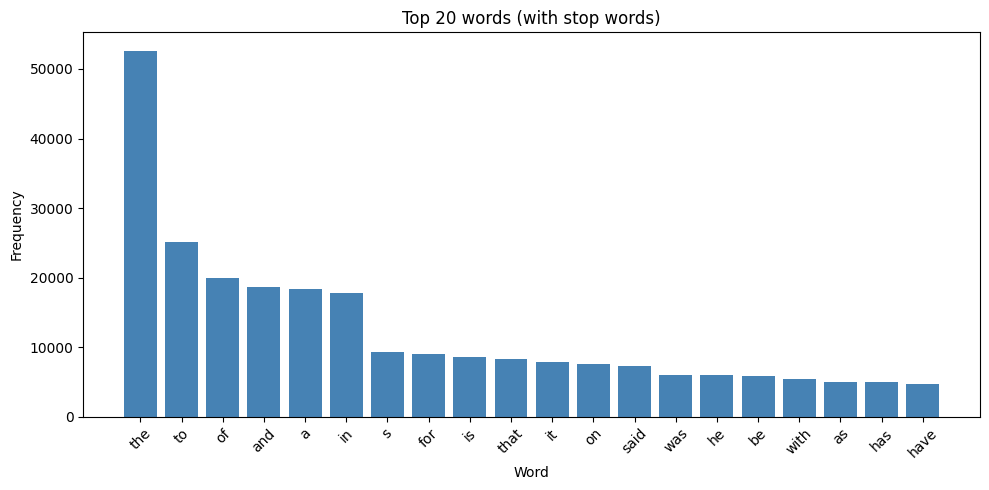

In [8]:
freq = Counter(words)
top = pd.DataFrame(freq.most_common(20), columns=["Word", "Frequency"])
print(top)

plt.figure(figsize=(10, 5))
plt.bar(top["Word"], top["Frequency"], color="steelblue")
plt.xticks(rotation=45)
plt.title("Top 20 words (with stop words)")
plt.xlabel("Word"); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()

## Step 4: Frequency distribution (without stop words like 'the', 'and')

          Word  Frequency
0         said       7255
1         year       2310
2       people       2045
3          new       1978
4         time       1322
5        world       1201
6   government       1160
7        years       1003
8         best        974
9         just        957
10        make        945
11        told        911
12        film        890
13        like        879
14        game        871
15       music        839
16      labour        804
17         bbc        778
18         set        762
19      number        760


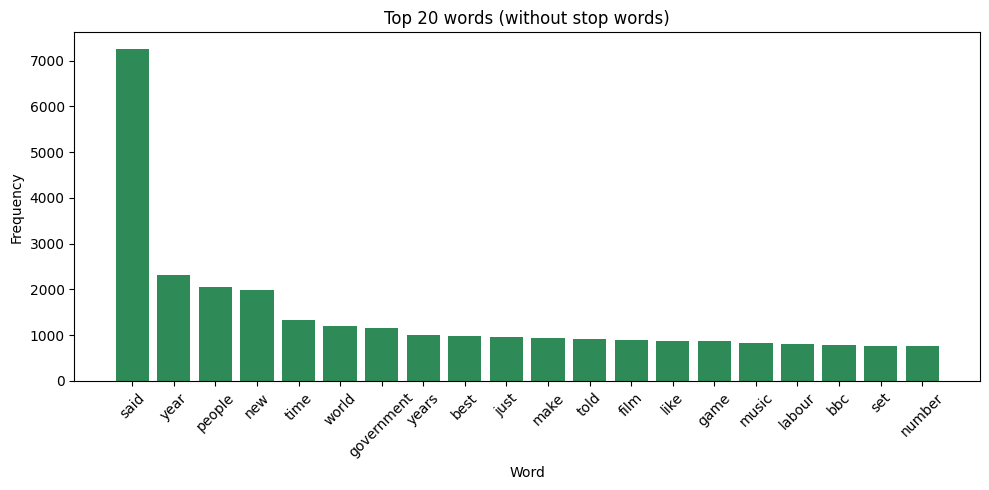

In [9]:
clean_words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
freq2 = Counter(clean_words)
top2 = pd.DataFrame(freq2.most_common(20), columns=["Word", "Frequency"])
print(top2)

plt.figure(figsize=(10, 5))
plt.bar(top2["Word"], top2["Frequency"], color="seagreen")
plt.xticks(rotation=45)
plt.title("Top 20 words (without stop words)")
plt.xlabel("Word"); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()